# Piece 5 — HVAC unit model L1 (datasheet + generic DX curve)

**Capacity.** EnergyPlus Engineering Reference, *Single-Speed Electric DX Air Cooling Coil*:

$$Q_{tot}(x, y) = Q_{rated}\,\frac{f(x, y)}{f(x_{rating}, y_{rating})},\qquad f = a + b\,x + c\,x^2 + d\,y + e\,y^2 + f\,x\,y$$

with $x$ = coil inlet wet-bulb and $y$ = outdoor dry-bulb (°C). The coefficients are the generic EnergyPlus example curve (evidence E-042…E-047, *literature*), **not** data for a specific unit. Normalising by $f$ at the datasheet's own rating point makes the model return exactly the datasheet capacity there.

**Sensible / latent split.** Apparatus dew point and bypass factor: $BF$ from the rated point and rated SHR, carried to other flows by $BF = e^{-A_0/\dot m}$.

In [1]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from core import loads, psychro
from core.coach import LoadTerm, SingleZoneCoach, UnitOperation, simulate
from core.unit import DXUnit, capacity_modifier, load_unit_card

dhf14 = load_unit_card("kaeser_noske_dhf14")
print(dhf14.report())

Kaeser-Noske DHF14-RVKE: 8 open datasheet item(s):
  - rating_indoor_dry_bulb: assumption (value empty)
  - rating_indoor_wet_bulb: assumption (value empty)
  - fresh_airflow: assumption (value empty)
  - compressor_power: assumption (value empty)
  - fan_power: assumption (value empty)
  - fan_position: assumption (value empty)
  - refrigerant: assumption (value empty)
  - rated_shr / rated_sensible_capacity: not on datasheet; falls back to evidence E-050


## Capacity vs. outdoor temperature — Kaeser-Noske DHF14

The datasheet gives **4.0 kW at 35 °C outside** but no indoor rating condition, so the coil-inlet wet-bulb $x$ of the rating point is unknown. **For this plot only**, $x$ = 19.4 °C is assumed (an AHRI-style value, *not* from the datasheet) to show the curve shape. The model itself refuses to run the DHF14 until the open items above are filled.

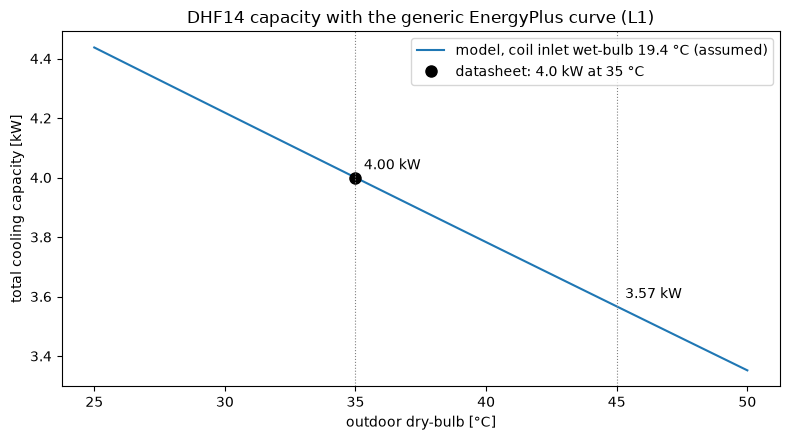

capacity at 45 °C = 3.57 kW (-10.8 % vs 35 °C)


In [2]:
Q_rated = dhf14.si("rated_total_cooling_capacity")      # W, datasheet
y_rated = dhf14.si("rating_outdoor_dry_bulb")            # degC, datasheet
x_assumed = 19.4                                         # degC, ASSUMED for illustration

y = np.linspace(25, 50, 101)
Q = Q_rated * capacity_modifier(x_assumed, y) / capacity_modifier(x_assumed, y_rated)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(y, Q / 1e3, label=f"model, coil inlet wet-bulb {x_assumed} °C (assumed)")
ax.plot([y_rated], [Q_rated / 1e3], "ko", ms=8, label="datasheet: 4.0 kW at 35 °C")
for T in (35, 45):
    q = Q_rated * capacity_modifier(x_assumed, T) / capacity_modifier(x_assumed, y_rated)
    ax.axvline(T, color="grey", ls=":", lw=0.8)
    ax.annotate(f"{q/1e3:.2f} kW", (T, q / 1e3), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("outdoor dry-bulb [°C]"); ax.set_ylabel("total cooling capacity [kW]")
ax.set_title("DHF14 capacity with the generic EnergyPlus curve (L1)")
ax.legend(); plt.tight_layout(); plt.show()
q45 = Q_rated * capacity_modifier(x_assumed, 45) / capacity_modifier(x_assumed, 35)
print(f"capacity at 45 °C = {q45/1e3:.2f} kW ({(q45/Q_rated-1)*100:+.1f} % vs 35 °C)")

## Coupled pull-down — verification coach + verification unit

> **Verification-only parameters** (coach A = 300 m², k = 1.2 W/m²K, C = 5·10⁶ J/K, V = 150 m³; unit `tests/data/verification_unit.yaml`: 30 kW, SHR 0.75, 6000 m³/h supply, 1200 m³/h fresh, 1.5 kW draw-through fan; 80 passengers; outside 45 °C / 25 % RH). Not data for a real coach or unit.

The zone receives supply air from the unit; fresh air enters **only** through the mixing box. Part load is fixed at 1.0 (controller: piece 7).

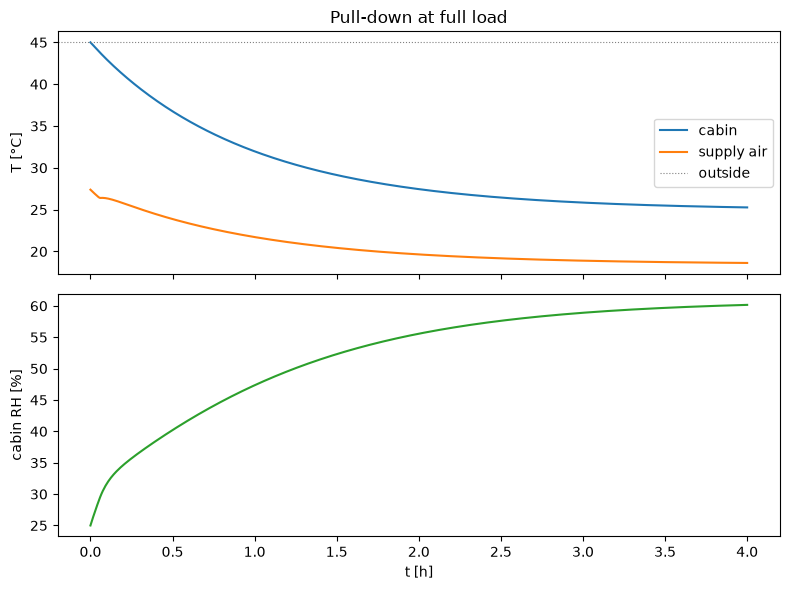

after 4 h: cabin 25.3 °C / 60 % RH, coil 28.8 kW (SHR 0.76), condensate 9.6 kg/h


In [3]:
unit = DXUnit.from_card(load_unit_card(root / "tests" / "data" / "verification_unit.yaml"))
coach = SingleZoneCoach("verification", 300.0, 1.2, 5e6, air_volume_m3=150.0)
T_out, RH_out = 45.0, 0.25
W0 = psychro.humidity_ratio(T_out, RH_out)
pax = LoadTerm("passengers", lambda t, T, W: loads.passengers(80, 70.0, 50.0))
df = simulate(coach, 45.0, T_out, 0.0, 0.0, t_end_s=4 * 3600, dt_out_s=30.0, W0=W0,
              loads=[pax], unit=UnitOperation(unit, "cooling", 1.0, RH_out))

h = df["t_s"] / 3600
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(h, df["T_C"], label="cabin")
ax1.plot(h, df["unit_T_supply_C"], label="supply air")
ax1.axhline(T_out, color="grey", ls=":", lw=0.8, label="outside")
ax1.set_ylabel("T [°C]"); ax1.legend(); ax1.set_title("Pull-down at full load")
ax2.plot(h, df["RH"] * 100, color="tab:green")
ax2.set_ylabel("cabin RH [%]"); ax2.set_xlabel("t [h]")
plt.tight_layout(); plt.show()
e = df.iloc[-1]
print(f"after 4 h: cabin {e['T_C']:.1f} °C / {e['RH']*100:.0f} % RH, coil {e['unit_Q_coil_total_W']/1e3:.1f} kW "
      f"(SHR {e['unit_shr']:.2f}), condensate {e['unit_m_condensate_kg_s']*3600:.1f} kg/h")